## Hydrodynamic model of the Southern North Sea

In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs
from helper import plot_shred_reconstruction

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSRED import mSHRED

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## Load Data and Measurement

In [3]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/Mesh_8000_elems_HD_v2.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)

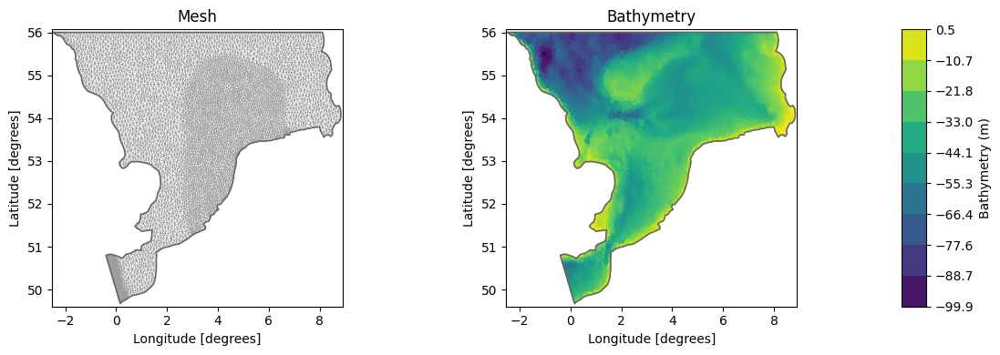

In [4]:
# plot geometry
geom = dfs.geometry

fig, axs = plt.subplots(1,2, figsize = (12,4))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
plt.show()

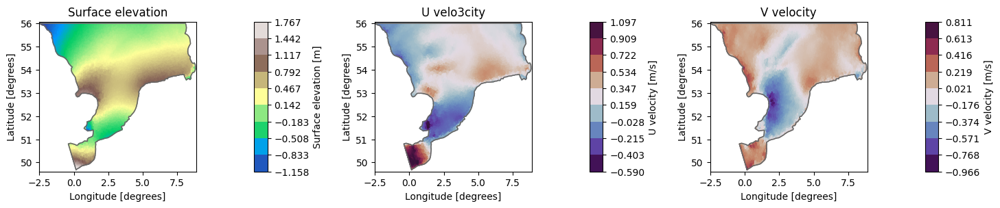

In [5]:
# plot a simulation
ds = dfs.read()

dsH = ds["Surface elevation"]
dsU = ds["U velocity"]
dsV = ds["V velocity"]

plot_time = ds.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
dsH.sel(time=plot_time).plot(ax=axs[0], title="Surface elevation", cmap = "terrain")
dsU.sel(time=plot_time).plot(ax=axs[1], title="U velo3city", cmap = "twilight_shifted")
dsV.sel(time=plot_time).plot(ax=axs[2], title="V velocity", cmap = "twilight_shifted")
plt.tight_layout()
plt.show()


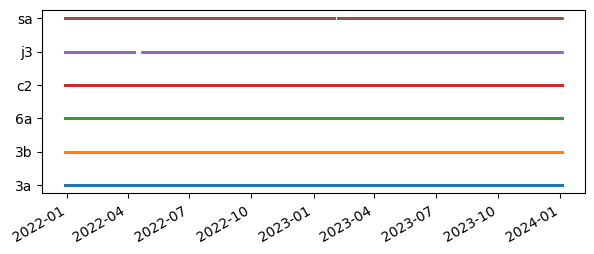

In [6]:
# sensor coverage

altlist = get_altimetry_obs()
ms.plotting.temporal_coverage(altlist)
plt.show()

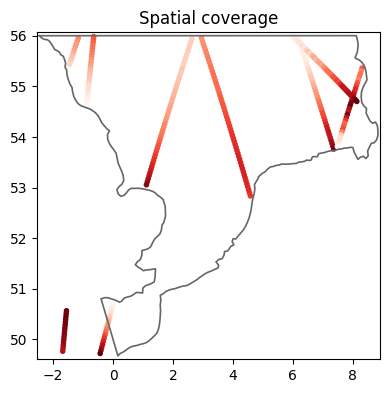

In [7]:
# Select stations with full temporal coverage and plot their spatial distribution, along with the intermittent stations.

altlist_jan2201 = [al.sel(time=slice("2022-01-01","2022-01-01")) for al in altlist]  
ms.plotting.spatial_overview(altlist_jan2201, mod=msh.geometry,figsize=(4,4));
plt.tight_layout() 

In [8]:
# Select stations with full temporal coverage

stations = []
availables = []
intermittent = []
for i in range(len(altlist)):
    stations.append(altlist[i])
    if ds.time.isin(altlist[i].time).all():
        availables.append(altlist[i])
    else:
        intermittent.append(altlist[i])

print(f"Total stations: {len(stations)}")
print(f"Stations with full temporal coverage: {len(availables)}")
print(f"Intermittent stations: {len(intermittent)}")

Total stations: 6
Stations with full temporal coverage: 0
Intermittent stations: 6


In [9]:
# Extract water level measurements

# We use a 25-min window to ensure we capture at least one measurement in each 30-min step, 
# If no measurement is found in the window, we keep NaN.

WINDOW = pd.Timedelta("25min")                                      # window size to look for measurements before each simulation time step
measurements = np.full((ds.time.shape[0], len(stations)), np.nan)   # initialize array to store measurements

# Loop through each station and each simulation time step to find the last measurement in the window
for i in range(len(stations)):

    stn_data = pd.read_csv(obs_fldr + "Altimetry_wl_" + stations[i].name + ".csv", index_col=0, parse_dates=True)   # Load station data
    wl = stn_data["water_level"]                        # Extract water level measurements 
    ds_times = pd.DatetimeIndex(ds.time.values)         # Simulation time steps as pandas DatetimeIndex

    # Loop through each simulation time step and find the last measurement in the window
    for j, t in enumerate(ds_times):
        # Select all measurements in the window (t - 25min, t]
        window_vals = wl[(wl.index > t - WINDOW) & (wl.index <= t)]
        if len(window_vals) > 0:
            measurements[j, i] = window_vals.iloc[-1]  # last measurement in window
        # else: stays NaN — no pass in this window

# free memory
del stn_data, wl, window_vals

In [10]:
# Extract the values and convert to torch tensors

# remove nans from H, U, V 
dsH = dsH.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsU = dsU.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsV = dsV.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]

# outputs
H = torch.tensor(dsH, dtype=torch.float32)
U = torch.tensor(dsU, dtype=torch.float32)
V = torch.tensor(dsV, dtype=torch.float32)

# inputs
measurements = torch.tensor(measurements, dtype=torch.float32)

# print the shape of the arrays
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements.shape)

# free memory
del dsH, dsU, dsV

H shape: torch.Size([35039, 8532])
U shape: torch.Size([35039, 8532])
V shape: torch.Size([35039, 8532])
Measurements shape: torch.Size([35039, 6])


In [11]:
ERRORS = []

## Idea 0: Only Available Sensors

In [12]:
# Extract measurements for always-available stations only
av_indices = [stations.index(s) for s in availables]
measurements_av = measurements[:, av_indices]

time_steps, _ = measurements_av.shape

#counts nans
nan_counts_intermittent = np.isnan(measurements[:, [stations.index(s) for s in intermittent]].numpy()).sum(axis=0)

#Stations
print("Intermittent stations:")
for i, s in enumerate(intermittent):
    print(
        f"\t{s.name}: "
        f"{time_steps - nan_counts_intermittent[i]} ok {nan_counts_intermittent[i]} nans",
        f" --> {100*(time_steps - nan_counts_intermittent[i])/time_steps:.1f}% coverage"
    )

Intermittent stations:
	3a: 659 ok 34380 nans  --> 1.9% coverage
	3b: 688 ok 34351 nans  --> 2.0% coverage
	6a: 751 ok 34288 nans  --> 2.1% coverage
	c2: 588 ok 34451 nans  --> 1.7% coverage
	j3: 721 ok 34318 nans  --> 2.1% coverage
	sa: 616 ok 34423 nans  --> 1.8% coverage


## Idea T.1.A: Median imputer

In [13]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="median"
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 6]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 6]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 6]) -> torch.Size([3504, 120])

Input shape for the model: 6
Output shape for the model: 120


Starting training...


Training:  60%|██████    | 120/200 [18:36<12:24,  9.30s/it, Train Loss=0.0084, Val Loss=0.0082, Patience=59, Best Val Loss=0.0082, LR=3.38e-04]

Early stopping at epoch 121
Training completed with best validation loss: 0.0082


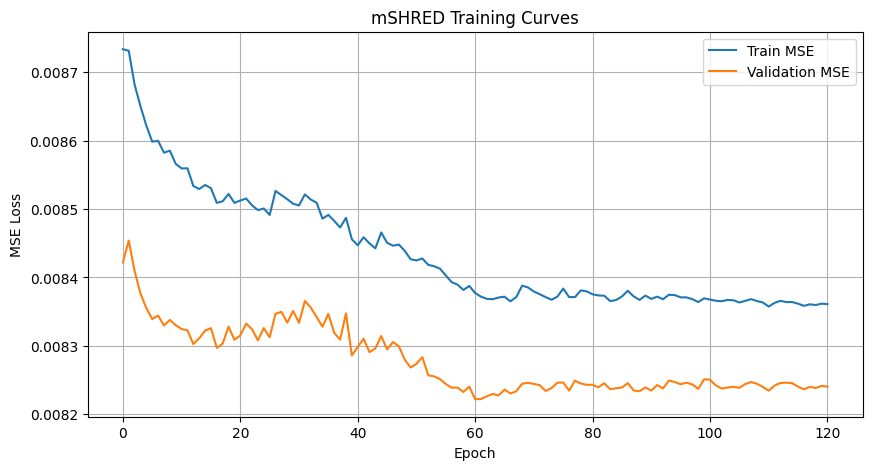

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.008361,0.008241,0.014719,0.193916,0.191668,0.245799


In [14]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + CNN",
    "type" : "(T.1.A) median imputation for missing sensors",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_1_A_median_imputation.png


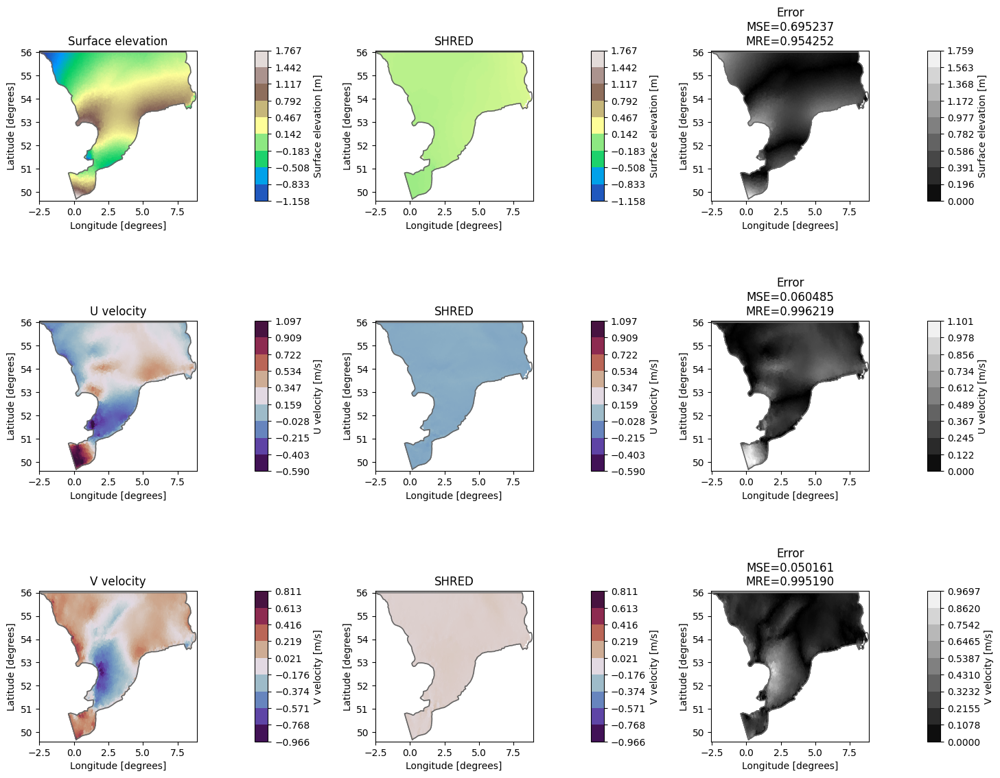

In [16]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_1_A_median_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea S.1.A: Median imputer 


Starting training...


Training:   0%|          | 0/200 [00:00<?, ?it/s]

Training: 100%|██████████| 200/200 [10:49<00:00,  3.25s/it, Train Loss=0.0083, Val Loss=0.0082, Patience=11, Best Val Loss=0.0082, LR=0.00e+00]

Training completed with best validation loss: 0.0082


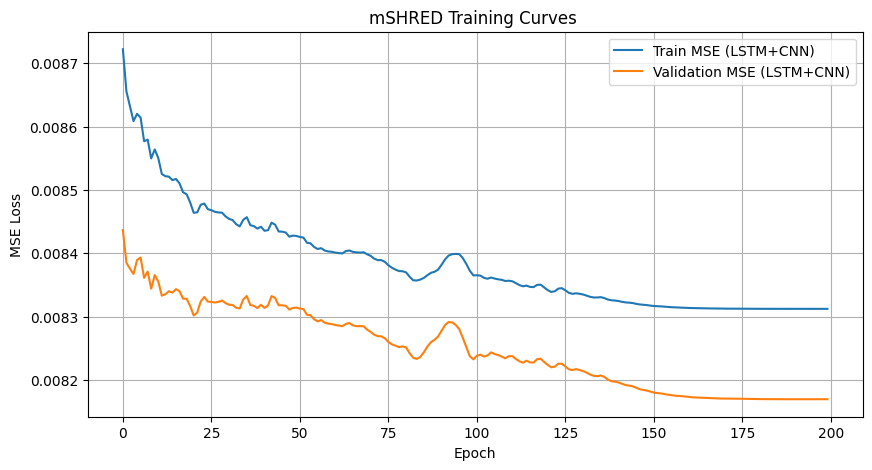

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.008361,0.008241,0.014719,0.193916,0.191668,0.245799
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.008312,0.008170,0.014767,0.193407,0.190894,0.246430


In [18]:

# mSHRED TRAINING (Idea S.1.A) - LSTM + CNN
model_args_s0 = dict(
    # Encoder
    encoder="lstm",
    input_size=nn_input_shape,
    hidden_size=32,
    num_layers=2,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args_s0).to(device)

train_errors_shred, valid_errors_shred = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors_shred, label='Train MSE (LSTM+CNN)')
plt.plot(valid_errors_shred, label='Validation MSE (LSTM+CNN)')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves ')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse_shred, train_mre_shred = evaluate(mshred, train_dataset)
val_mse_shred, val_mre_shred = evaluate(mshred, val_dataset)
test_mse_shred, test_mre_shred = evaluate(mshred, test_dataset)
test_error = {
    "model": "(mSHRED) LSTM + CNN",
    "type": "(S.1.A) median imputation for missing sensors",
    "train-mse": float(train_mse_shred),
    "val-mse": float(val_mse_shred),
    "test-mse": float(test_mse_shred),
    "train-mre": float(train_mre_shred),
    "val-mre": float(val_mre_shred),
    "test-mre": float(test_mre_shred),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_S_1_A_median_imputation.png


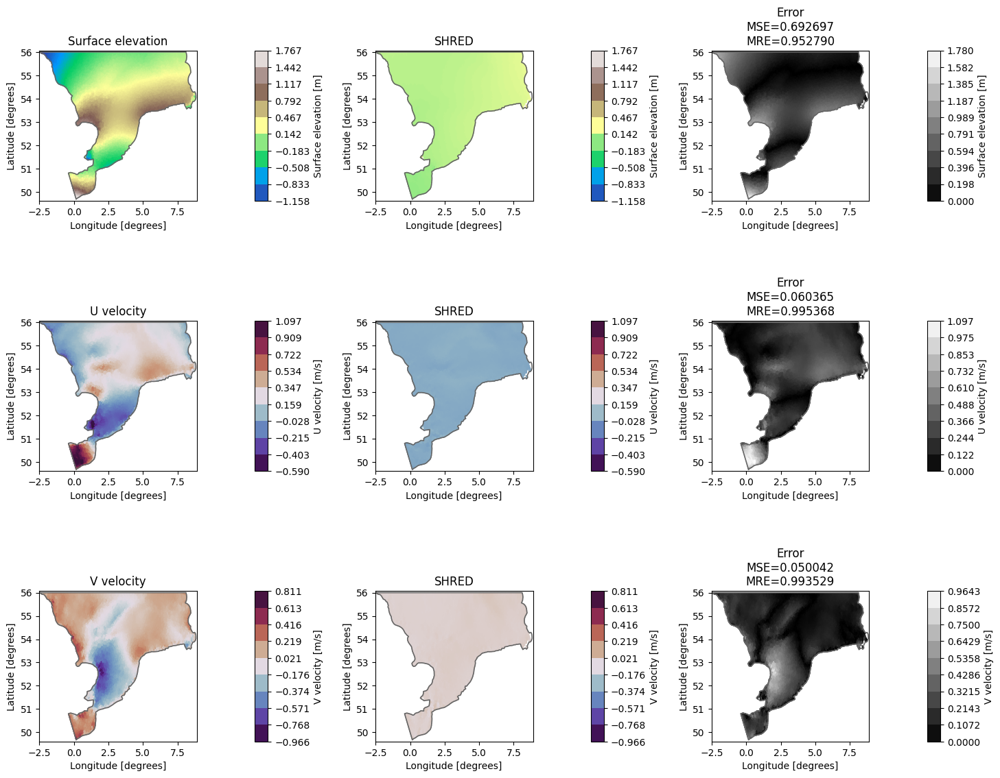

In [19]:

# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="S_1_A_median_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager


## Idea T.1.B: Mean imputer

In [20]:
# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="mean"
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 6]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 6]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 6]) -> torch.Size([3504, 120])

Input shape for the model: 6
Output shape for the model: 120


Starting training...


Training:  62%|██████▏   | 123/200 [17:00<10:38,  8.29s/it, Train Loss=0.0084, Val Loss=0.0082, Patience=59, Best Val Loss=0.0082, LR=3.16e-04]

Early stopping at epoch 124
Training completed with best validation loss: 0.0082


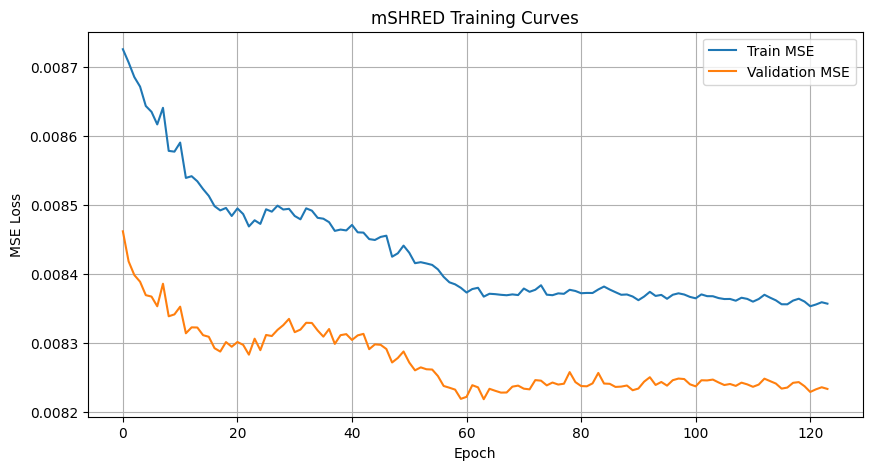

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.008361,0.008241,0.014719,0.193916,0.191668,0.245799
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.008312,0.008170,0.014767,0.193407,0.190894,0.246430
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.008357,0.008233,0.014720,0.193842,0.191556,0.245820


In [21]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + CNN",
    "type" : "(T.1.B) mean imputation for missing sensors",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_1_B_mean_imputation.png


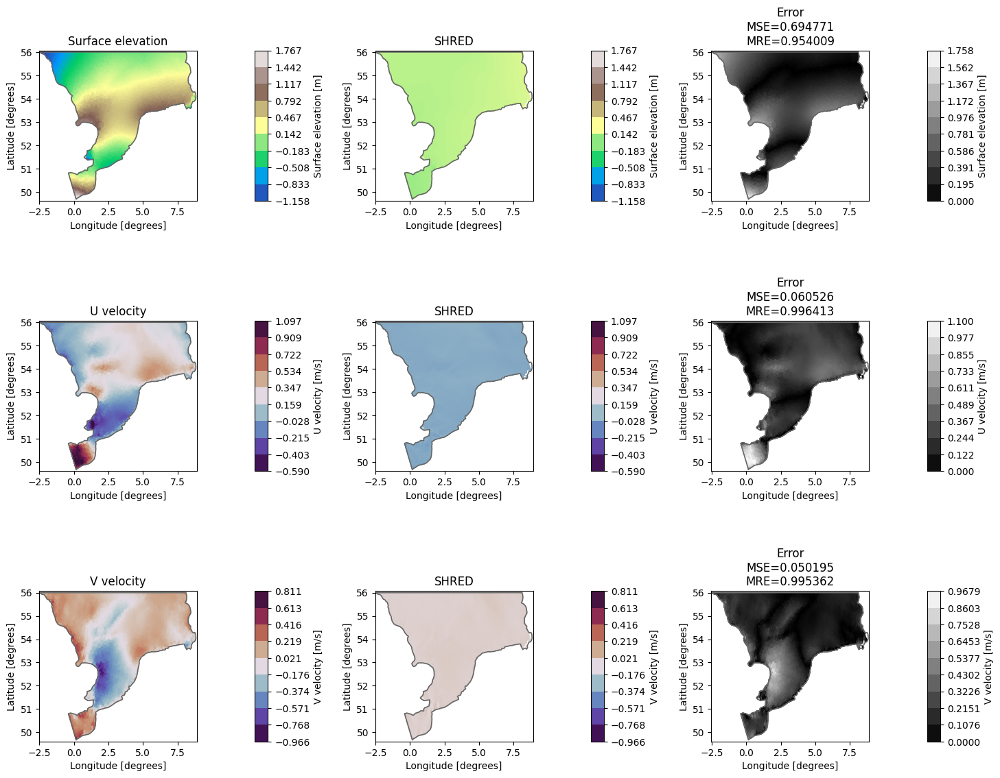

In [22]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_1_B_mean_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea S.1.B: Mean imputer

Starting training...


Training: 100%|██████████| 200/200 [10:05<00:00,  3.03s/it, Train Loss=0.0083, Val Loss=0.0082, Patience=11, Best Val Loss=0.0082, LR=0.00e+00]

Training completed with best validation loss: 0.0082


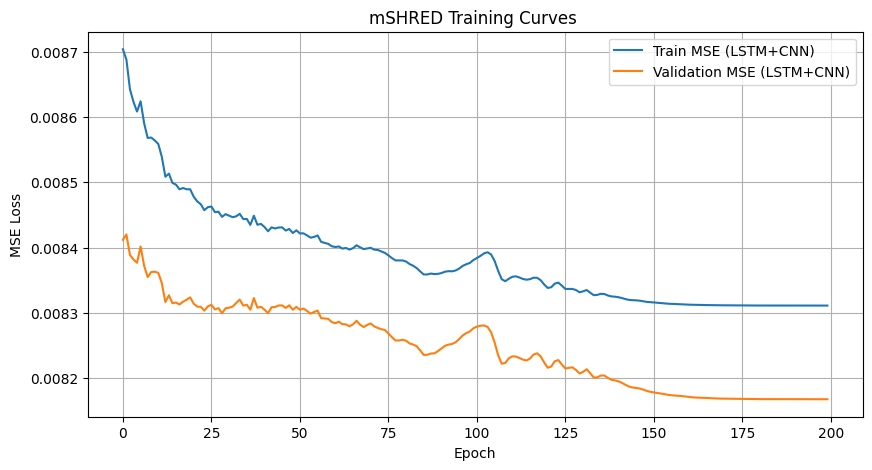

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.008361,0.008241,0.014719,0.193916,0.191668,0.245799
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.008312,0.008170,0.014767,0.193407,0.190894,0.246430
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.008357,0.008233,0.014720,0.193842,0.191556,0.245820
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.008311,0.008168,0.014761,0.193379,0.190850,0.246389


In [23]:

# mSHRED TRAINING (Idea S.1.B) - LSTM + CNN
model_args_s0 = dict(
    # Encoder
    encoder="lstm",
    input_size=nn_input_shape,
    hidden_size=32,
    num_layers=2,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args_s0).to(device)

train_errors_shred, valid_errors_shred = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors_shred, label='Train MSE (LSTM+CNN)')
plt.plot(valid_errors_shred, label='Validation MSE (LSTM+CNN)')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves ')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse_shred, train_mre_shred = evaluate(mshred, train_dataset)
val_mse_shred, val_mre_shred = evaluate(mshred, val_dataset)
test_mse_shred, test_mre_shred = evaluate(mshred, test_dataset)
test_error = {
    "model": "(mSHRED) LSTM + CNN",
    "type": "(S.1.B) mean imputation for missing sensors",
    "train-mse": float(train_mse_shred),
    "val-mse": float(val_mse_shred),
    "test-mse": float(test_mse_shred),
    "train-mre": float(train_mre_shred),
    "val-mre": float(val_mre_shred),
    "test-mre": float(test_mre_shred),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_S_1_B_mean_imputation.png


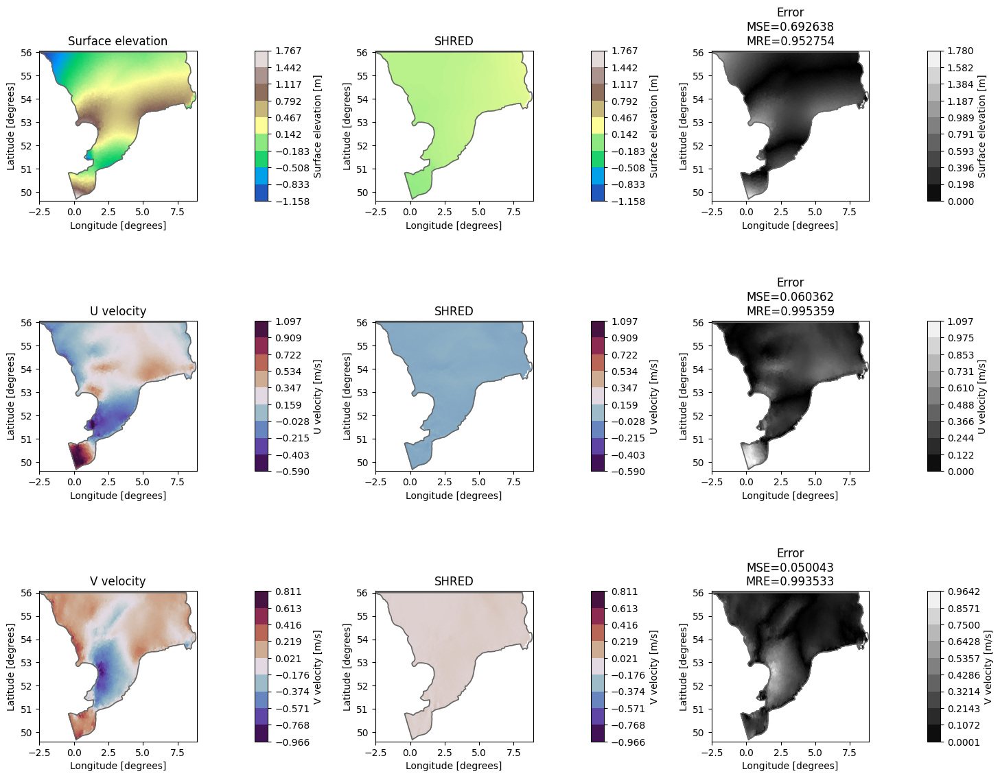

In [24]:

# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="S_1_B_mean_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager


## Idea T.1.C: Last value imputer

In [25]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="last_value"
 )
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 6]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 6]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 6]) -> torch.Size([3504, 120])

Input shape for the model: 6
Output shape for the model: 120


Starting training...


Training:  62%|██████▏   | 124/200 [17:06<10:28,  8.27s/it, Train Loss=0.0084, Val Loss=0.0082, Patience=59, Best Val Loss=0.0082, LR=3.09e-04]


Early stopping at epoch 125
Training completed with best validation loss: 0.0082


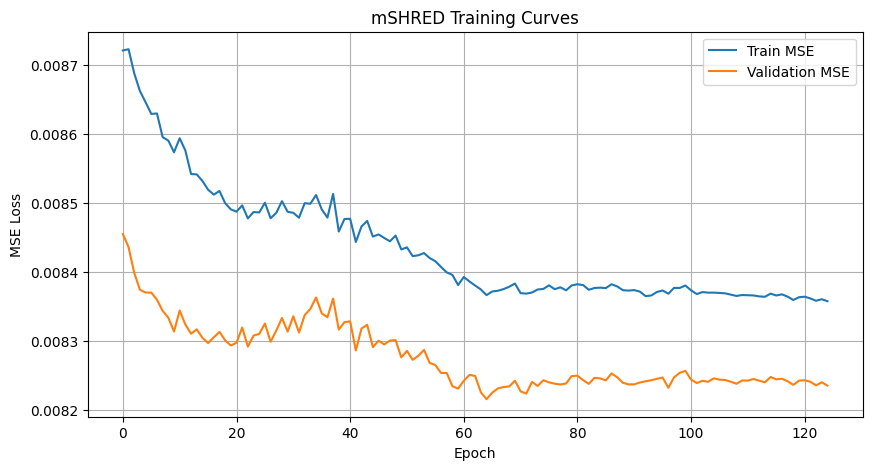

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.008361,0.008241,0.014719,0.193916,0.191668,0.245799
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.008312,0.008170,0.014767,0.193407,0.190894,0.246430
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.008357,0.008233,0.014720,0.193842,0.191556,0.245820
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.008311,0.008168,0.014761,0.193379,0.190850,0.246389
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.008358,0.008236,0.014729,0.193847,0.191579,0.245895


In [26]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + CNN",
    "type" : "(T.1.C) last value imputation for missing sensors",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_1_C_last_value_imputation.png


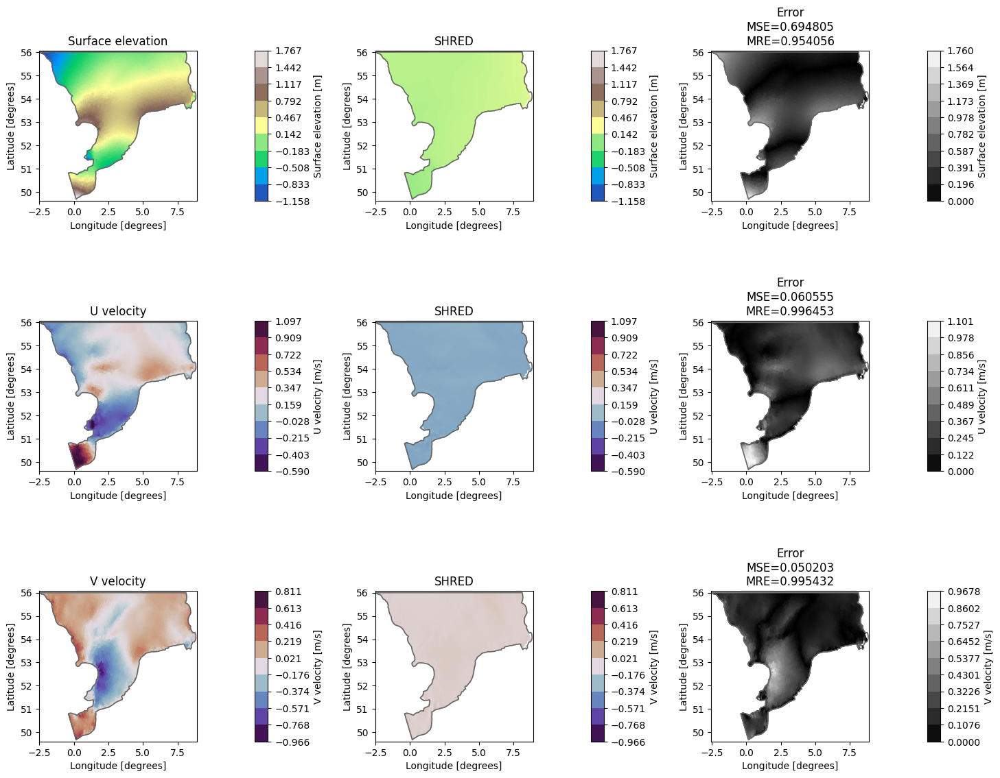

In [27]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_1_C_last_value_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea S.1.C: Last value imputer

Starting training...


Training:   0%|          | 0/200 [00:00<?, ?it/s]

Training: 100%|██████████| 200/200 [09:37<00:00,  2.89s/it, Train Loss=0.0077, Val Loss=0.0080, Patience=29, Best Val Loss=0.0080, LR=0.00e+00]

Training completed with best validation loss: 0.0080


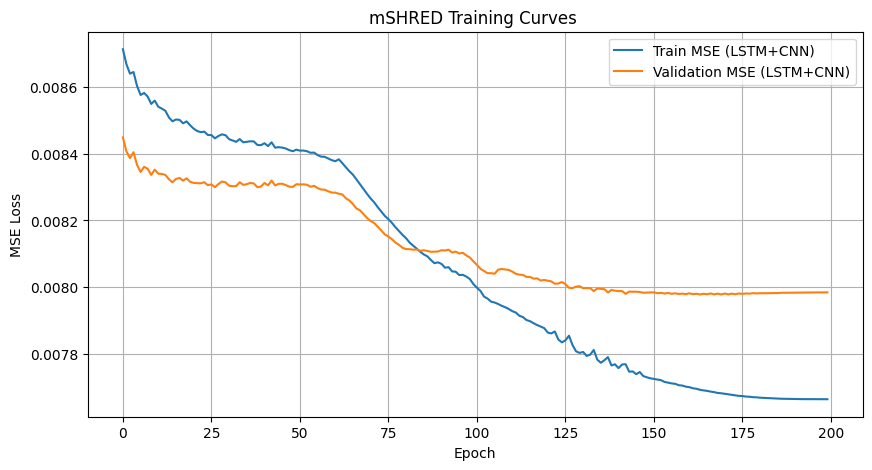

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.008361,0.008241,0.014719,0.193916,0.191668,0.245799
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.008312,0.008170,0.014767,0.193407,0.190894,0.246430
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.008357,0.008233,0.014720,0.193842,0.191556,0.245820
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.008311,0.008168,0.014761,0.193379,0.190850,0.246389
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.008358,0.008236,0.014729,0.193847,0.191579,0.245895
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.007663,0.007984,0.014835,0.185271,0.188077,0.246285


In [28]:

# mSHRED TRAINING (Idea S.1.C) - LSTM + CNN
model_args_s0 = dict(
    # Encoder
    encoder="lstm",
    input_size=nn_input_shape,
    hidden_size=32,
    num_layers=2,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args_s0).to(device)

train_errors_shred, valid_errors_shred = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors_shred, label='Train MSE (LSTM+CNN)')
plt.plot(valid_errors_shred, label='Validation MSE (LSTM+CNN)')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves ')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse_shred, train_mre_shred = evaluate(mshred, train_dataset)
val_mse_shred, val_mre_shred = evaluate(mshred, val_dataset)
test_mse_shred, test_mre_shred = evaluate(mshred, test_dataset)
test_error = {
    "model": "(mSHRED) LSTM + CNN",
    "type": "(S.1.C) last value imputation for missing sensors",
    "train-mse": float(train_mse_shred),
    "val-mse": float(val_mse_shred),
    "test-mse": float(test_mse_shred),
    "train-mre": float(train_mre_shred),
    "val-mre": float(val_mre_shred),
    "test-mre": float(test_mre_shred),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_S_1_C_last_value_imputation.png


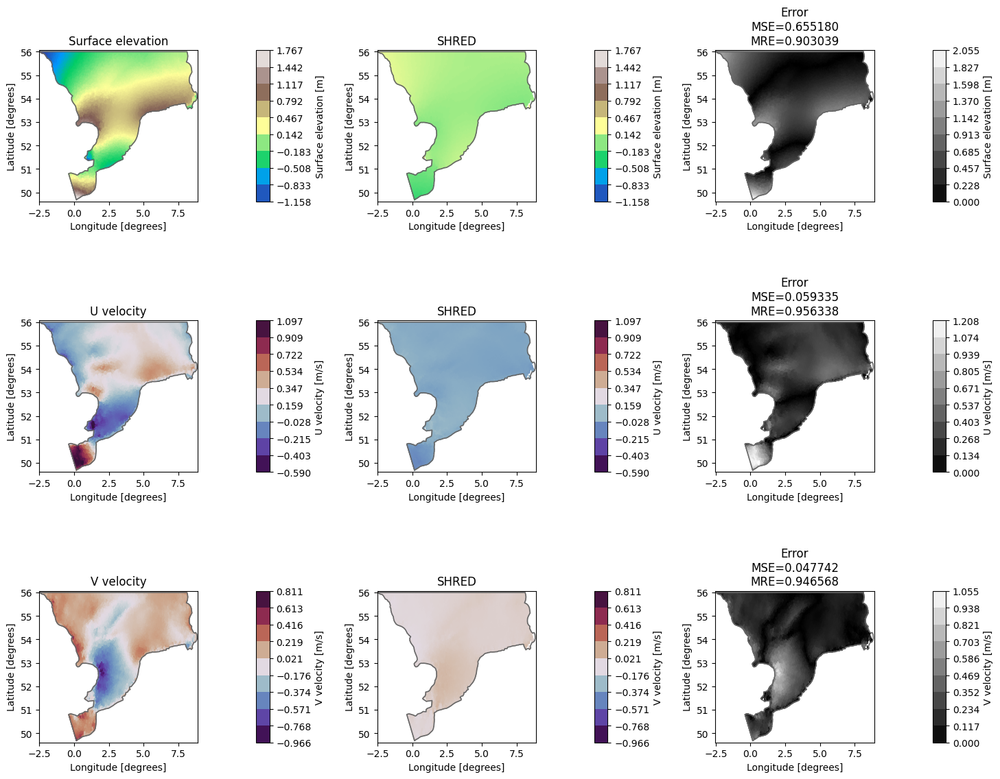

In [29]:

# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="S_1_C_last_value_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager


## Idea 2.A: GRUD

In [30]:

# Data manager
lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset, X_mean = manager.prepare(verbose = True, masking_type="grud")

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 206211 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 4, 24, 6]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 4, 24, 6]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 4, 24, 6]) -> torch.Size([3504, 120])

Input shape for the model: 6
Output shape for the model: 120


Starting training...


Training:  57%|█████▊    | 115/200 [16:30<12:11,  8.61s/it, Train Loss=0.0072, Val Loss=0.0083, Patience=59, Best Val Loss=0.0081, LR=3.76e-04]

Early stopping at epoch 116
Training completed with best validation loss: 0.0081


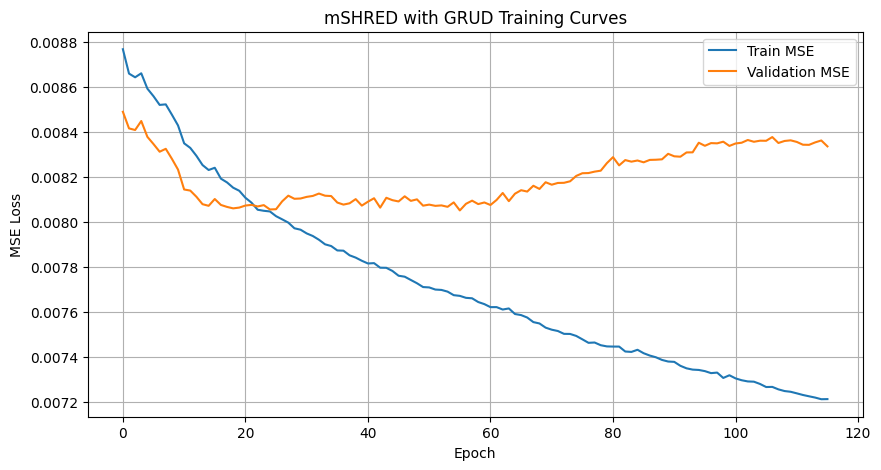

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.008361,0.008241,0.014719,0.193916,0.191668,0.245799
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.008312,0.008170,0.014767,0.193407,0.190894,0.246430
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.008357,0.008233,0.014720,0.193842,0.191556,0.245820
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.008311,0.008168,0.014761,0.193379,0.190850,0.246389
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.008358,0.008236,0.014729,0.193847,0.191579,0.245895
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.007663,0.007984,0.014835,0.185271,0.188077,0.246285
6,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.007214,0.008336,0.014890,0.178397,0.192296,0.247023


In [31]:
# GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="grud",
    input_size=nn_input_shape,
    hidden_size=32,
    X_mean=X_mean,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED with GRUD Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): GRUD + CNN",
    "type" : "(2.A) GRUD masking",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_2_A_GRUD_masking.png


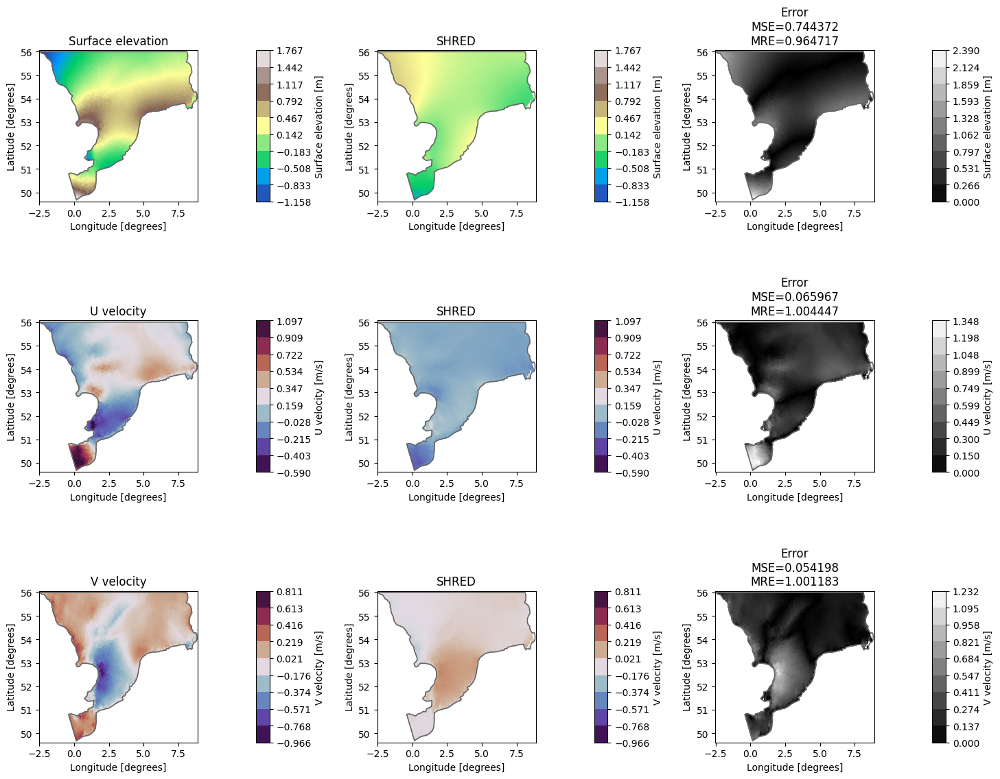

In [32]:

# mSHRED RECONSTRUCTION

engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_grud, ds_error_grud = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="2_A_GRUD_masking")

del engine, test_reconstruction, ds_grud, ds_error_grud, mshred


## Idea 2.B: Attn AGRUD


Starting training...


Training:  40%|███▉      | 79/200 [15:17<23:24, 11.61s/it, Train Loss=0.0075, Val Loss=0.0082, Patience=59, Best Val Loss=0.0080, LR=6.55e-04]

Early stopping at epoch 80
Training completed with best validation loss: 0.0080


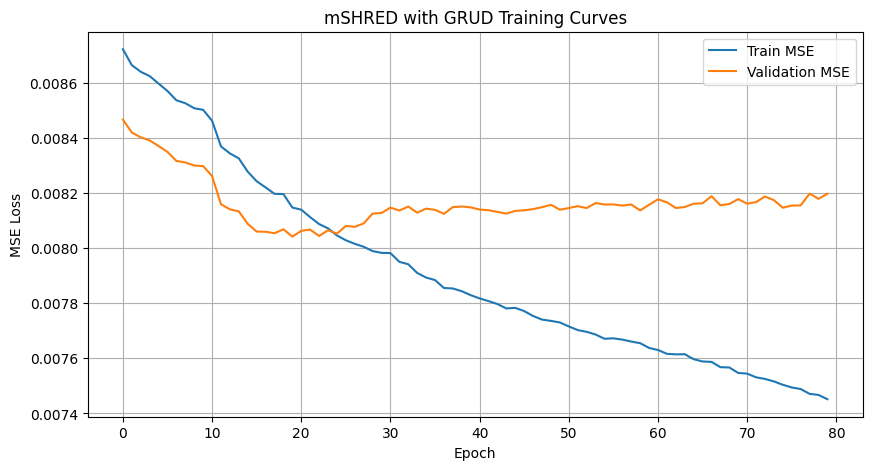

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.008361,0.008241,0.014719,0.193916,0.191668,0.245799
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.008312,0.008170,0.014767,0.193407,0.190894,0.246430
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.008357,0.008233,0.014720,0.193842,0.191556,0.245820
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.008311,0.008168,0.014761,0.193379,0.190850,0.246389
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.008358,0.008236,0.014729,0.193847,0.191579,0.245895
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.007663,0.007984,0.014835,0.185271,0.188077,0.246285
6,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.007214,0.008336,0.014890,0.178397,0.192296,0.247023
7,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.007452,0.008197,0.014757,0.181852,0.190942,0.245919


In [33]:
# GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="att_grud",
    input_size=nn_input_shape,
    hidden_size=32,
    X_mean=X_mean,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED with GRUD Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): attnGRUD + CNN",
    "type" : "(2.B) GRUD masking",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_2_B_attnGRUD_masking.png


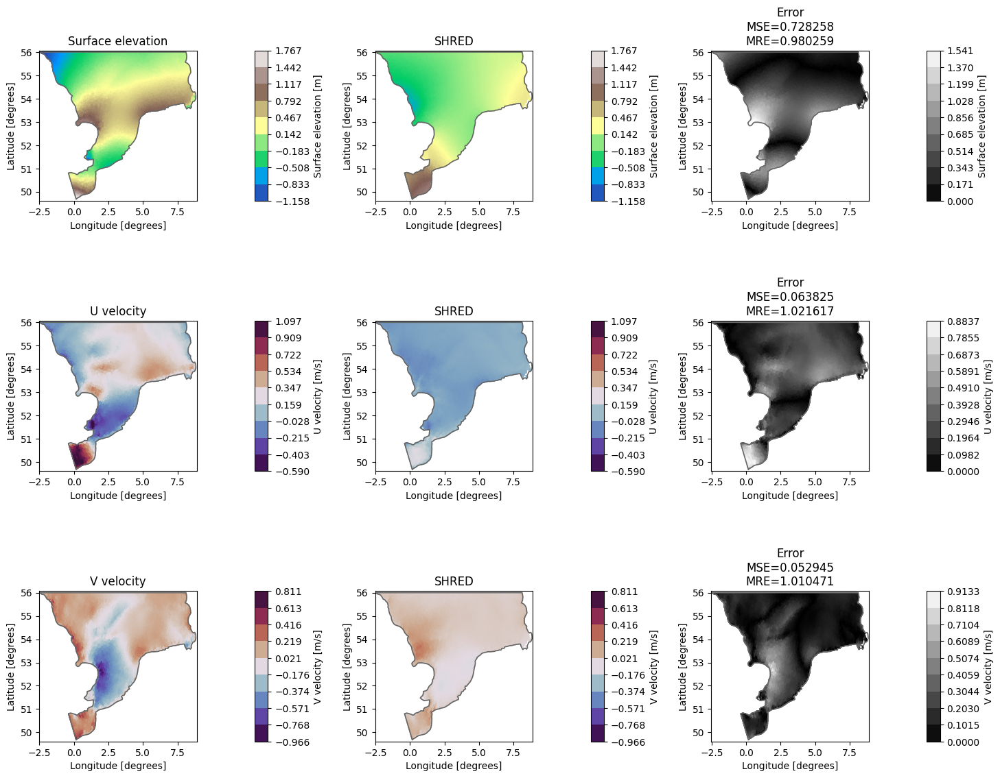

In [34]:

# mSHRED RECONSTRUCTION

engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_grud, ds_error_grud = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="2_B_attnGRUD_masking")

del engine, test_reconstruction, ds_grud, ds_error_grud, mshred, manager


## Masking

In [36]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = 12, measurements = measurements)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True, masking_type="mask_data")

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 206211 



Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 206211

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 6]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 6]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 6]) -> torch.Size([3504, 120])

Input shape for the model: 6
Output shape for the model: 120


## Idea 3.0: TSHRED

Starting training...


Training:  67%|██████▋   | 134/200 [21:38<10:39,  9.69s/it, Train Loss=0.0084, Val Loss=0.0082, Patience=59, Best Val Loss=0.0082, LR=2.39e-04]

Early stopping at epoch 135
Training completed with best validation loss: 0.0082


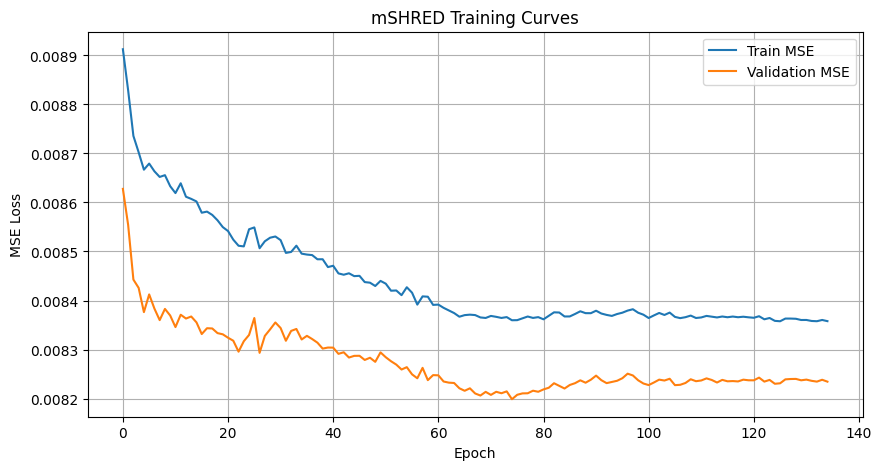

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.008361,0.008241,0.014719,0.193916,0.191668,0.245799
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.008312,0.008170,0.014767,0.193407,0.190894,0.246430
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.008357,0.008233,0.014720,0.193842,0.191556,0.245820
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.008311,0.008168,0.014761,0.193379,0.190850,0.246389
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.008358,0.008236,0.014729,0.193847,0.191579,0.245895
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.007663,0.007984,0.014835,0.185271,0.188077,0.246285
6,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.007214,0.008336,0.014890,0.178397,0.192296,0.247023
7,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.007452,0.008197,0.014757,0.181852,0.190942,0.245919
8,(mSHRED): TR + MLP,(3.0) TSHRED,0.008358,0.008234,0.014713,0.193816,0.191529,0.245707


In [37]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type= "mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset,masking_type= "mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset,masking_type= "mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset,masking_type= "mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.0) TSHRED",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_0_tshred.png


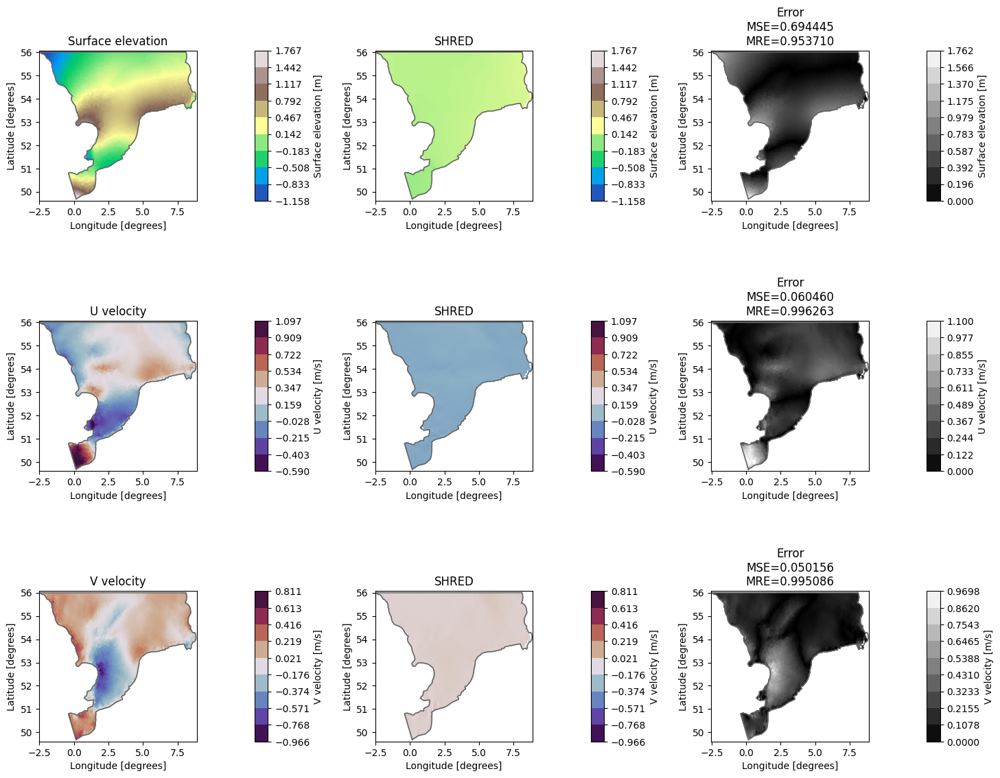

In [38]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_0_tshred")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.A: Mask double channels

Starting training...


Training: 100%|██████████| 200/200 [32:56<00:00,  9.88s/it, Train Loss=0.0075, Val Loss=0.0078, Patience=45, Best Val Loss=0.0078, LR=0.00e+00]

Training completed with best validation loss: 0.0078


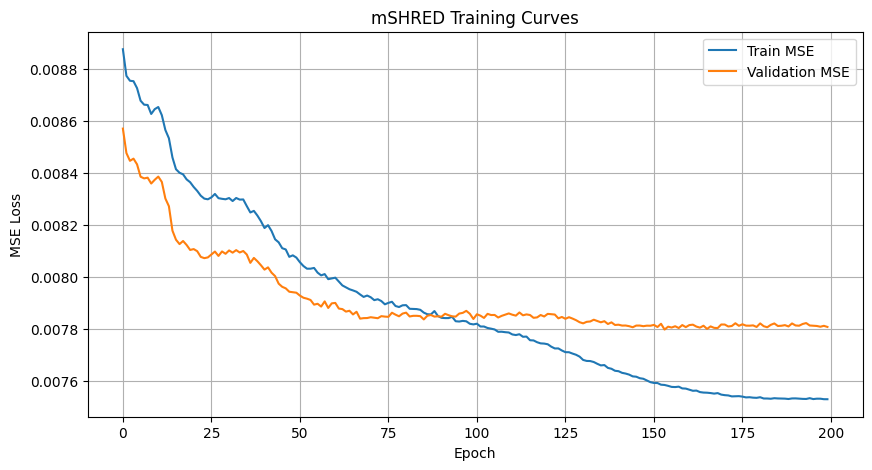

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.008361,0.008241,0.014719,0.193916,0.191668,0.245799
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.008312,0.008170,0.014767,0.193407,0.190894,0.246430
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.008357,0.008233,0.014720,0.193842,0.191556,0.245820
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.008311,0.008168,0.014761,0.193379,0.190850,0.246389
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.008358,0.008236,0.014729,0.193847,0.191579,0.245895
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.007663,0.007984,0.014835,0.185271,0.188077,0.246285
6,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.007214,0.008336,0.014890,0.178397,0.192296,0.247023
7,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.007452,0.008197,0.014757,0.181852,0.190942,0.245919
8,(mSHRED): TR + MLP,(3.0) TSHRED,0.008358,0.008234,0.014713,0.193816,0.191529,0.245707
9,(mSHRED): TR + MLP,(3.A) Mask double channels,0.007532,0.007815,0.014594,0.182771,0.185969,0.244279


In [39]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=True,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type= "mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset,masking_type= "mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset,masking_type= "mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset,masking_type= "mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.A) Mask double channels",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_A_mask_double_channels.png


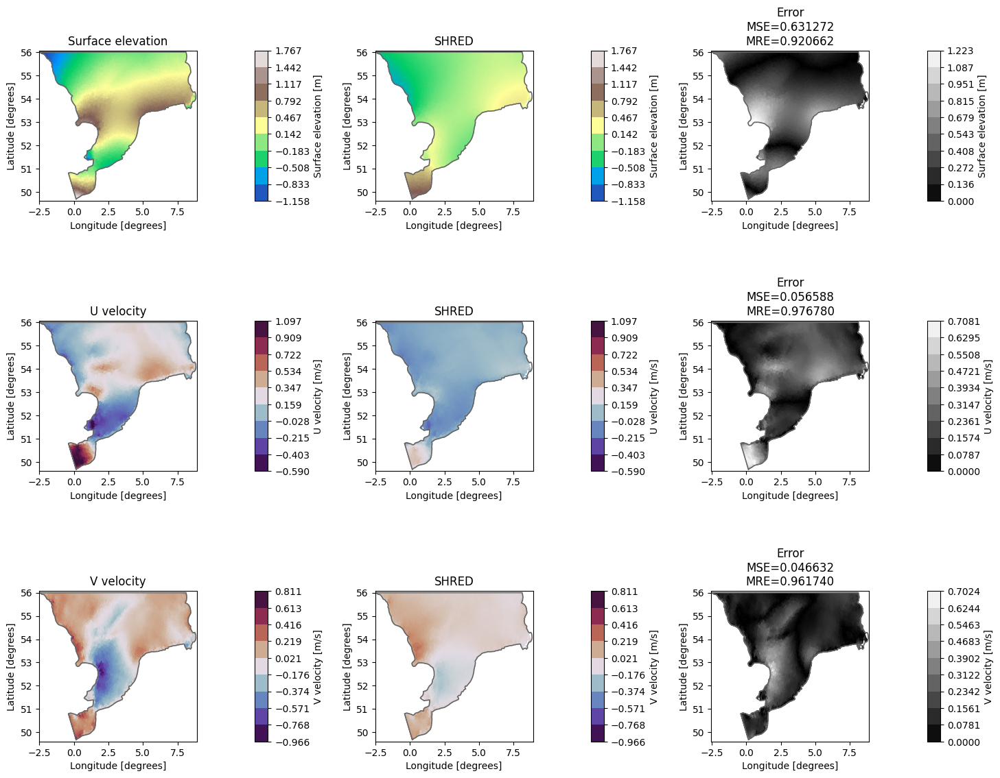

In [40]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_A_mask_double_channels")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.B: Mask in the hidden space

Starting training...


Training: 100%|██████████| 200/200 [33:10<00:00,  9.95s/it, Train Loss=0.0079, Val Loss=0.0078, Patience=11, Best Val Loss=0.0078, LR=0.00e+00]

Training completed with best validation loss: 0.0078


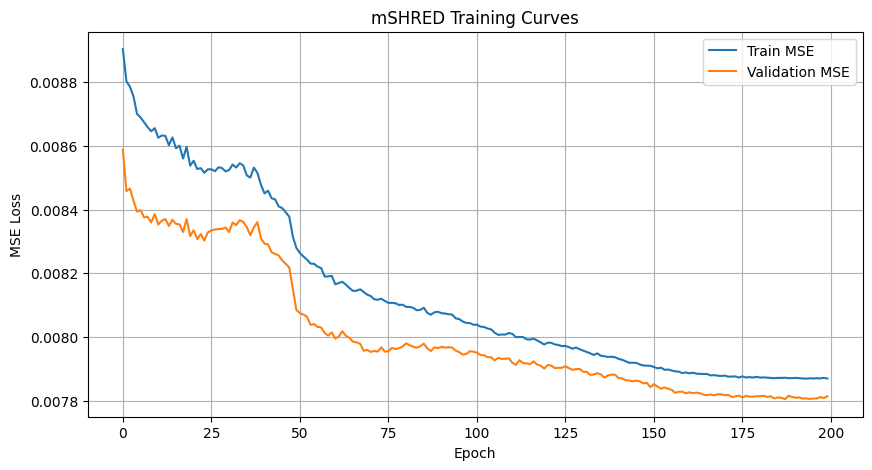

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.008361,0.008241,0.014719,0.193916,0.191668,0.245799
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.008312,0.008170,0.014767,0.193407,0.190894,0.246430
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.008357,0.008233,0.014720,0.193842,0.191556,0.245820
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.008311,0.008168,0.014761,0.193379,0.190850,0.246389
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.008358,0.008236,0.014729,0.193847,0.191579,0.245895
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.007663,0.007984,0.014835,0.185271,0.188077,0.246285
6,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.007214,0.008336,0.014890,0.178397,0.192296,0.247023
7,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.007452,0.008197,0.014757,0.181852,0.190942,0.245919
8,(mSHRED): TR + MLP,(3.0) TSHRED,0.008358,0.008234,0.014713,0.193816,0.191529,0.245707
9,(mSHRED): TR + MLP,(3.A) Mask double channels,0.007532,0.007815,0.014594,0.182771,0.185969,0.244279


In [41]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_hidden_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.B) Mask the hidden state",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_B_mask_hidden_state.png


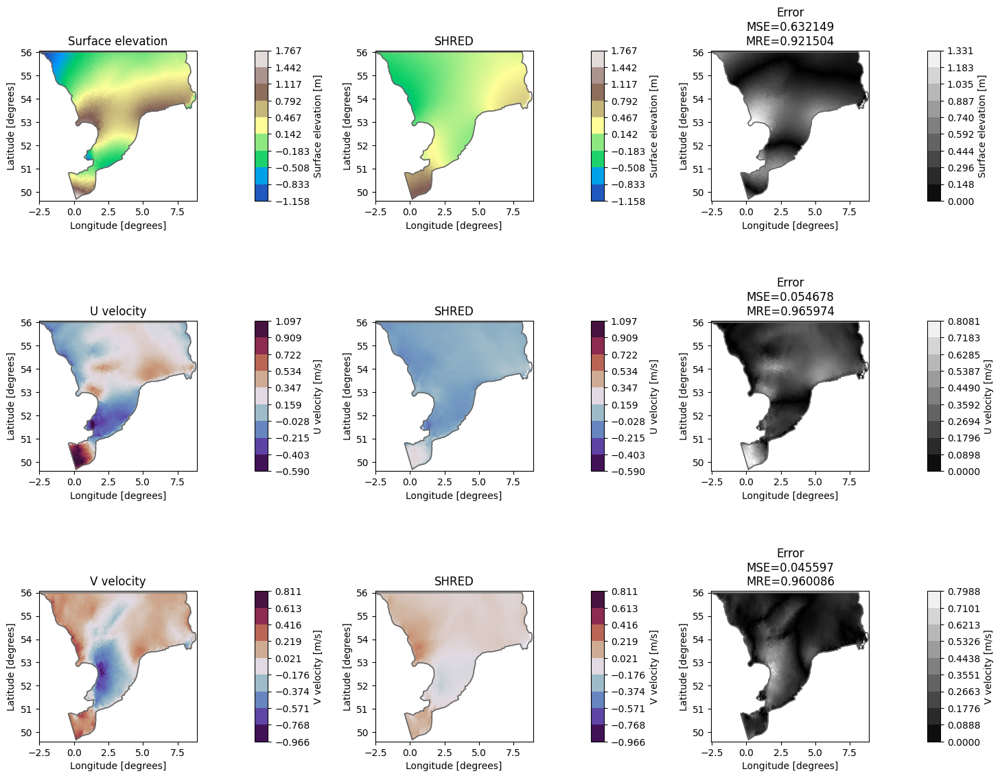

In [42]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_B_mask_hidden_state")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.C: Mask in the attention block

Starting training...


Training: 100%|██████████| 200/200 [33:20<00:00, 10.00s/it, Train Loss=0.0077, Val Loss=0.0078, Patience=20, Best Val Loss=0.0078, LR=0.00e+00]

Training completed with best validation loss: 0.0078


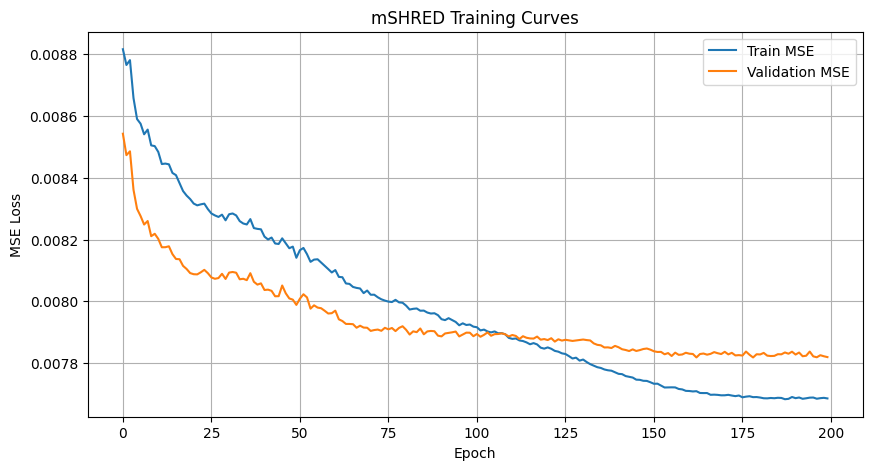

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.008361,0.008241,0.014719,0.193916,0.191668,0.245799
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.008312,0.008170,0.014767,0.193407,0.190894,0.246430
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.008357,0.008233,0.014720,0.193842,0.191556,0.245820
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.008311,0.008168,0.014761,0.193379,0.190850,0.246389
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.008358,0.008236,0.014729,0.193847,0.191579,0.245895
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.007663,0.007984,0.014835,0.185271,0.188077,0.246285
6,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.007214,0.008336,0.014890,0.178397,0.192296,0.247023
7,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.007452,0.008197,0.014757,0.181852,0.190942,0.245919
8,(mSHRED): TR + MLP,(3.0) TSHRED,0.008358,0.008234,0.014713,0.193816,0.191529,0.245707
9,(mSHRED): TR + MLP,(3.A) Mask double channels,0.007532,0.007815,0.014594,0.182771,0.185969,0.244279


In [43]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.C) Mask in the attention block",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_C_mask_attention_block.png


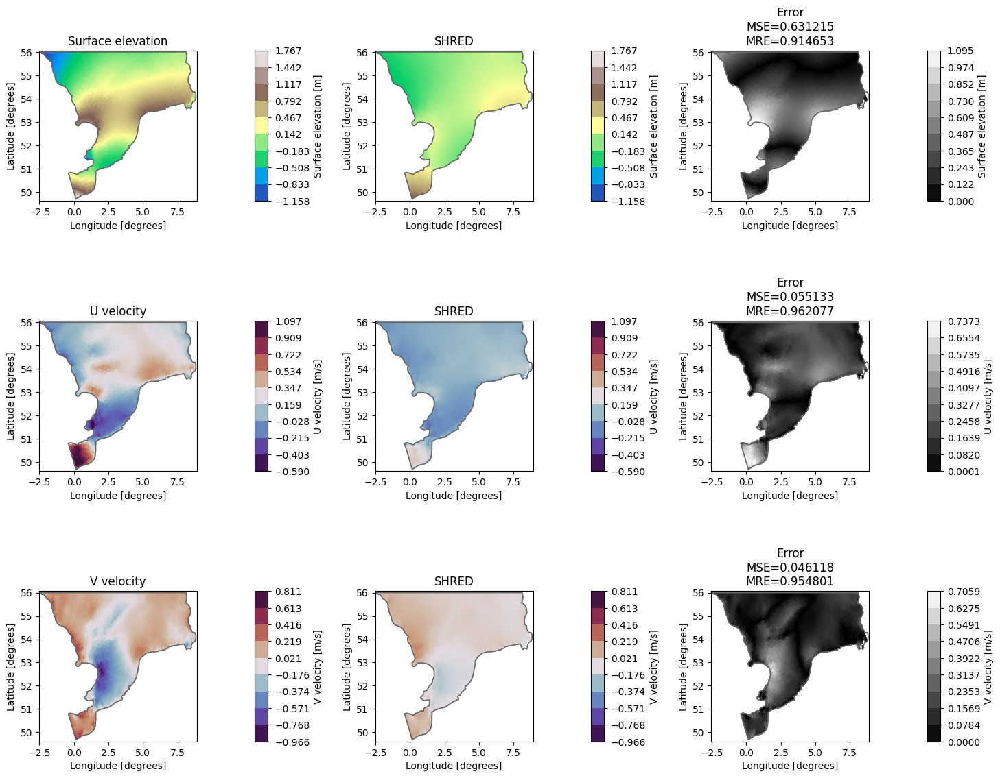

In [44]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_C_mask_attention_block")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.D: Attention mask + double channels

Starting training...


Training: 100%|██████████| 200/200 [33:26<00:00, 10.03s/it, Train Loss=0.0075, Val Loss=0.0078, Patience=7, Best Val Loss=0.0078, LR=0.00e+00] 

Training completed with best validation loss: 0.0078


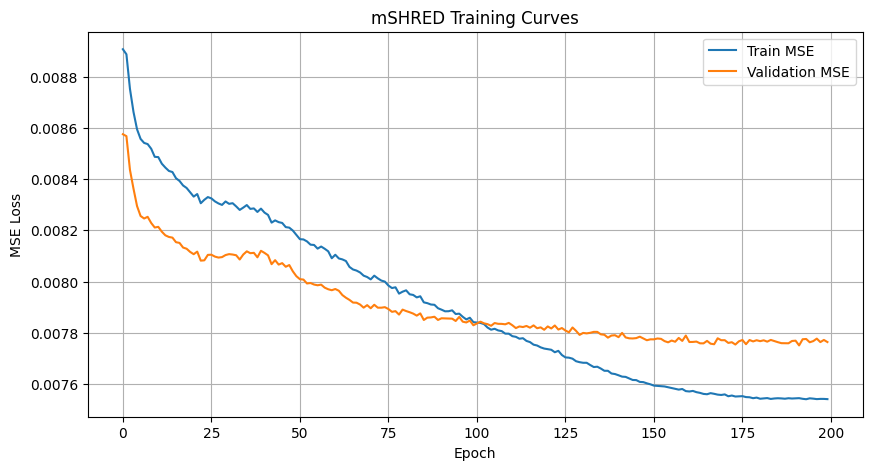

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.008361,0.008241,0.014719,0.193916,0.191668,0.245799
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.008312,0.008170,0.014767,0.193407,0.190894,0.246430
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.008357,0.008233,0.014720,0.193842,0.191556,0.245820
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.008311,0.008168,0.014761,0.193379,0.190850,0.246389
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.008358,0.008236,0.014729,0.193847,0.191579,0.245895
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.007663,0.007984,0.014835,0.185271,0.188077,0.246285
6,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.007214,0.008336,0.014890,0.178397,0.192296,0.247023
7,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.007452,0.008197,0.014757,0.181852,0.190942,0.245919
8,(mSHRED): TR + MLP,(3.0) TSHRED,0.008358,0.008234,0.014713,0.193816,0.191529,0.245707
9,(mSHRED): TR + MLP,(3.A) Mask double channels,0.007532,0.007815,0.014594,0.182771,0.185969,0.244279


In [45]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=True,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.D) Double masking",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_D_double_masking.png


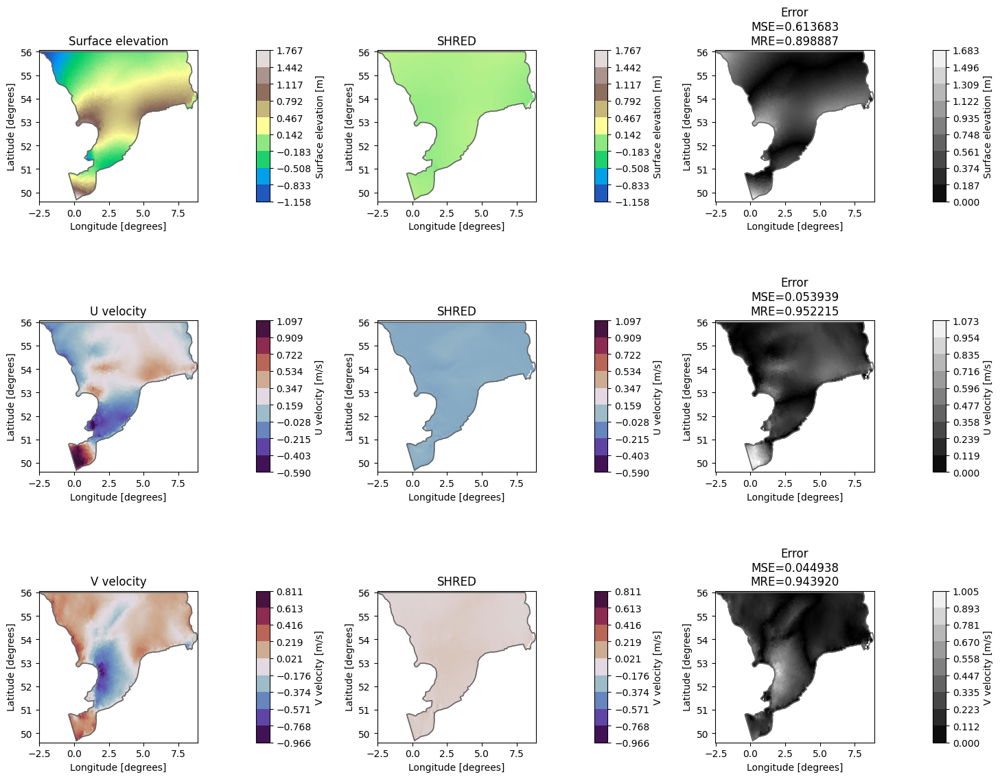

In [46]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_D_double_masking")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.E: learn the mask in the softmax


Starting training...


Training:  68%|██████▊   | 135/200 [26:20<12:40, 11.71s/it, Train Loss=0.0084, Val Loss=0.0082, Patience=59, Best Val Loss=0.0082, LR=2.32e-04]

Early stopping at epoch 136
Training completed with best validation loss: 0.0082


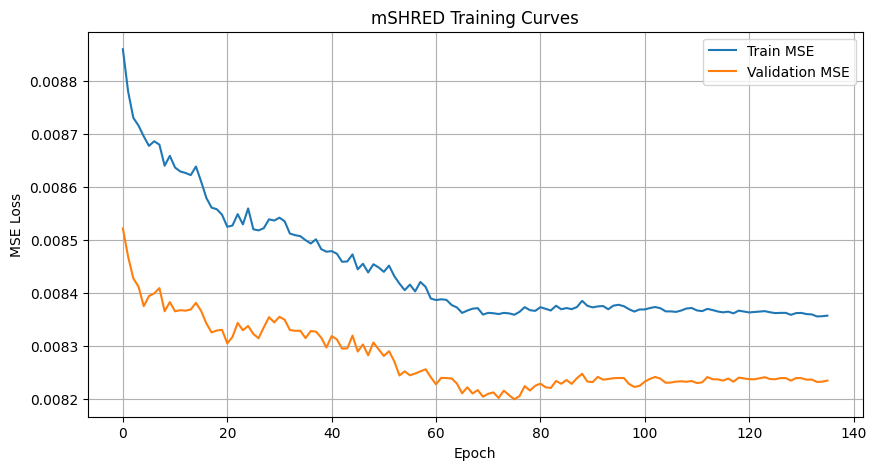

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.008361,0.008241,0.014719,0.193916,0.191668,0.245799
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.008312,0.008170,0.014767,0.193407,0.190894,0.246430
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.008357,0.008233,0.014720,0.193842,0.191556,0.245820
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.008311,0.008168,0.014761,0.193379,0.190850,0.246389
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.008358,0.008236,0.014729,0.193847,0.191579,0.245895
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.007663,0.007984,0.014835,0.185271,0.188077,0.246285
6,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.007214,0.008336,0.014890,0.178397,0.192296,0.247023
7,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.007452,0.008197,0.014757,0.181852,0.190942,0.245919
8,(mSHRED): TR + MLP,(3.0) TSHRED,0.008358,0.008234,0.014713,0.193816,0.191529,0.245707
9,(mSHRED): TR + MLP,(3.A) Mask double channels,0.007532,0.007815,0.014594,0.182771,0.185969,0.244279


In [47]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.E) Transformer Learned mask",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_D_learn_mask_softmax.png


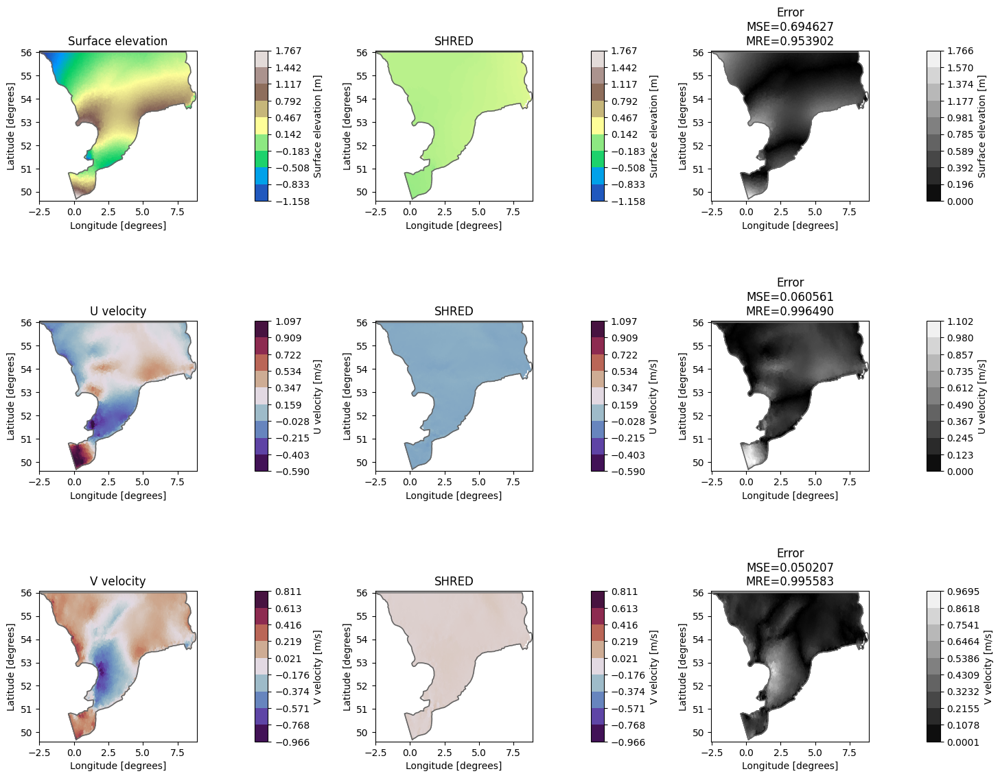

In [48]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_D_learn_mask_softmax")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.F: Learned mask + double channels


Starting training...


Training:  66%|██████▋   | 133/200 [25:41<12:56, 11.59s/it, Train Loss=0.0084, Val Loss=0.0082, Patience=59, Best Val Loss=0.0082, LR=2.45e-04]

Early stopping at epoch 134
Training completed with best validation loss: 0.0082


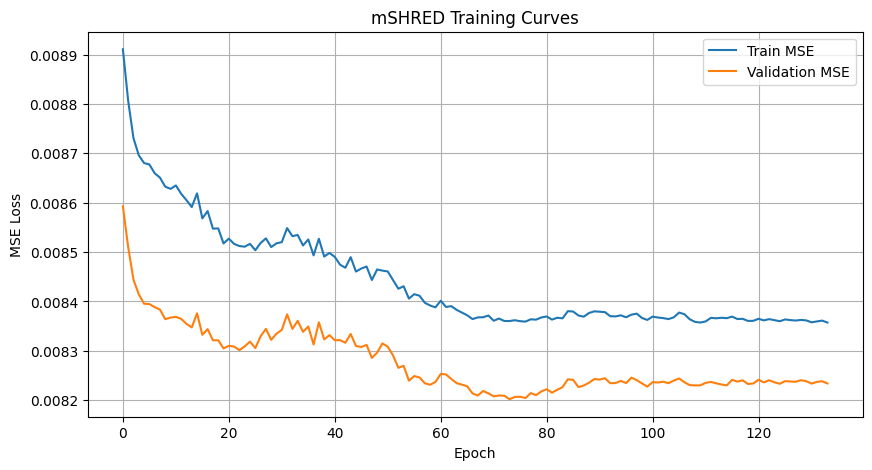

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.008361,0.008241,0.014719,0.193916,0.191668,0.245799
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.008312,0.008170,0.014767,0.193407,0.190894,0.246430
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.008357,0.008233,0.014720,0.193842,0.191556,0.245820
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.008311,0.008168,0.014761,0.193379,0.190850,0.246389
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.008358,0.008236,0.014729,0.193847,0.191579,0.245895
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.007663,0.007984,0.014835,0.185271,0.188077,0.246285
6,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.007214,0.008336,0.014890,0.178397,0.192296,0.247023
7,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.007452,0.008197,0.014757,0.181852,0.190942,0.245919
8,(mSHRED): TR + MLP,(3.0) TSHRED,0.008358,0.008234,0.014713,0.193816,0.191529,0.245707
9,(mSHRED): TR + MLP,(3.A) Mask double channels,0.007532,0.007815,0.014594,0.182771,0.185969,0.244279


In [49]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=True,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.F) Transformer Learned mask + double channels",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_F_learn_mask_double_channels.png


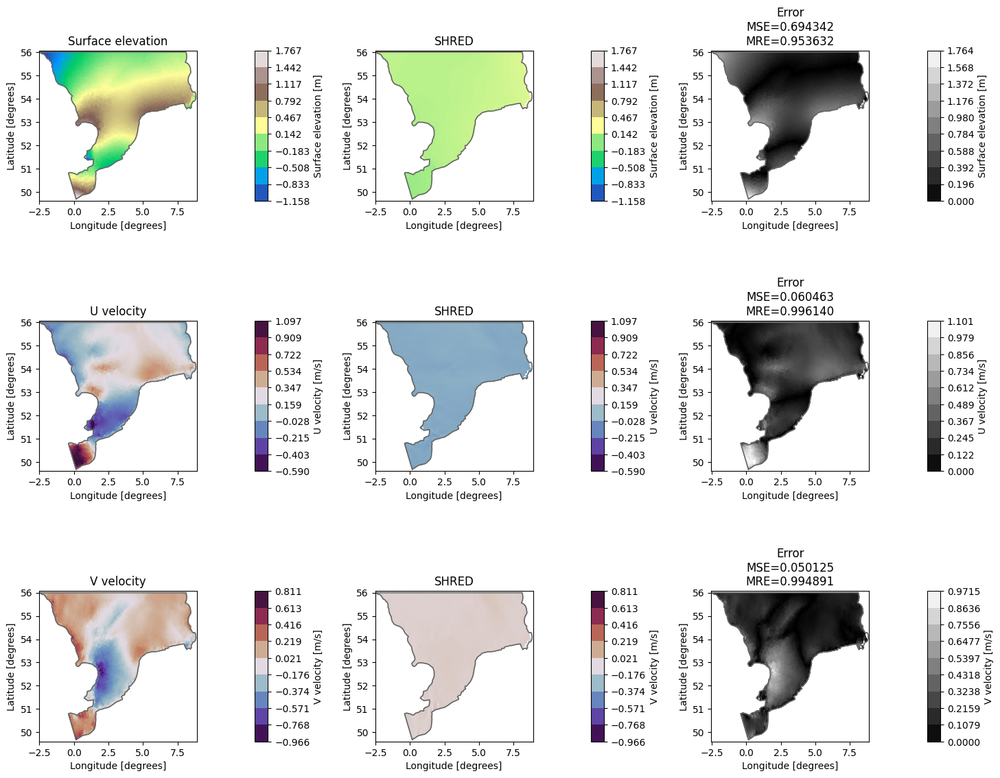

In [50]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_F_learn_mask_double_channels")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Results

In [51]:
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.008361,0.008241,0.014719,0.193916,0.191668,0.245799
1,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.008312,0.008170,0.014767,0.193407,0.190894,0.246430
2,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.008357,0.008233,0.014720,0.193842,0.191556,0.245820
3,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.008311,0.008168,0.014761,0.193379,0.190850,0.246389
4,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.008358,0.008236,0.014729,0.193847,0.191579,0.245895
5,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.007663,0.007984,0.014835,0.185271,0.188077,0.246285
6,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.007214,0.008336,0.014890,0.178397,0.192296,0.247023
7,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.007452,0.008197,0.014757,0.181852,0.190942,0.245919
8,(mSHRED): TR + MLP,(3.0) TSHRED,0.008358,0.008234,0.014713,0.193816,0.191529,0.245707
9,(mSHRED): TR + MLP,(3.A) Mask double channels,0.007532,0.007815,0.014594,0.182771,0.185969,0.244279


<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>val-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>val-mre</th>
      <th>test-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR + CNN</td>
      <td>(T.1.A) median imputation for missing sensors</td>
      <td>0.008361</td>
      <td>0.008241</td>
      <td>0.014719</td>
      <td>0.193916</td>
      <td>0.191668</td>
      <td>0.245799</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.A) median imputation for missing sensors</td>
      <td>0.008312</td>
      <td>0.008170</td>
      <td>0.014767</td>
      <td>0.193407</td>
      <td>0.190894</td>
      <td>0.246430</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR + CNN</td>
      <td>(T.1.B) mean imputation for missing sensors</td>
      <td>0.008357</td>
      <td>0.008233</td>
      <td>0.014720</td>
      <td>0.193842</td>
      <td>0.191556</td>
      <td>0.245820</td>
    </tr>
    <tr>
      <th>3</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.B) mean imputation for missing sensors</td>
      <td>0.008311</td>
      <td>0.008168</td>
      <td>0.014761</td>
      <td>0.193379</td>
      <td>0.190850</td>
      <td>0.246389</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): TR + CNN</td>
      <td>(T.1.C) last value imputation for missing sensors</td>
      <td>0.008358</td>
      <td>0.008236</td>
      <td>0.014729</td>
      <td>0.193847</td>
      <td>0.191579</td>
      <td>0.245895</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.C) last value imputation for missing sensors</td>
      <td>0.007663</td>
      <td>0.007984</td>
      <td>0.014835</td>
      <td>0.185271</td>
      <td>0.188077</td>
      <td>0.246285</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): GRUD + CNN</td>
      <td>(2.A) GRUD masking</td>
      <td>0.007214</td>
      <td>0.008336</td>
      <td>0.014890</td>
      <td>0.178397</td>
      <td>0.192296</td>
      <td>0.247023</td>
    </tr>
    <tr>
      <th>7</th>
      <td>(mSHRED): attnGRUD + CNN</td>
      <td>(2.B) GRUD masking</td>
      <td>0.007452</td>
      <td>0.008197</td>
      <td>0.014757</td>
      <td>0.181852</td>
      <td>0.190942</td>
      <td>0.245919</td>
    </tr>
    <tr>
      <th>8</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.0) TSHRED</td>
      <td>0.008358</td>
      <td>0.008234</td>
      <td>0.014713</td>
      <td>0.193816</td>
      <td>0.191529</td>
      <td>0.245707</td>
    </tr>
    <tr>
      <th>9</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.A) Mask double channels</td>
      <td>0.007532</td>
      <td>0.007815</td>
      <td>0.014594</td>
      <td>0.182771</td>
      <td>0.185969</td>
      <td>0.244279</td>
    </tr>
    <tr>
      <th>10</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.B) Mask the hidden state</td>
      <td>0.007872</td>
      <td>0.007806</td>
      <td>0.014529</td>
      <td>0.187529</td>
      <td>0.186097</td>
      <td>0.243742</td>
    </tr>
    <tr>
      <th>11</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.C) Mask in the attention block</td>
      <td>0.007684</td>
      <td>0.007824</td>
      <td>0.014561</td>
      <td>0.184920</td>
      <td>0.186109</td>
      <td>0.243981</td>
    </tr>
    <tr>
      <th>12</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.D) Double masking</td>
      <td>0.007542</td>
      <td>0.007773</td>
      <td>0.014514</td>
      <td>0.182926</td>
      <td>0.185492</td>
      <td>0.243624</td>
    </tr>
    <tr>
      <th>13</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.E) Transformer Learned mask</td>
      <td>0.008357</td>
      <td>0.008234</td>
      <td>0.014728</td>
      <td>0.193788</td>
      <td>0.191521</td>
      <td>0.245835</td>
    </tr>
    <tr>
      <th>14</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.F) Transformer Learned mask + double channels</td>
      <td>0.008357</td>
      <td>0.008234</td>
      <td>0.014712</td>
      <td>0.193813</td>
      <td>0.191528</td>
      <td>0.245687</td>
    </tr>
  </tbody>
</table>
</div>

## 